# From Basis Functions to Kernels — an Intuitive Bridge Example

**A guided rewrite of the first version of this notebook** · Based on Low et al., *Function Spaces Without Kernels: Learning Compact Hilbert Space Representations* (arXiv:2509.20605, especially §§3–4).

> **The one-sentence idea:** A **primal** model predicts by adding a few **basis functions**; its **dual** predicts by adding **kernel functions attached to observations**. With the induced kernel, they produce *exactly the same prediction*. A function encoder learns the basis functions from many related problems.

**What you'll be able to explain after running this notebook**
1. What is a space of functions, and what does a basis function represent?
2. A kernel is an inner product of **feature vectors at two positions**. It is *not necessarily* a spatial-distance function or a mechanics Green's function.
3. Why $K=\Phi\Phi^T$ is a valid kernel matrix, and why the *basis Gram matrix* $G=\Phi^T\Phi$ is different.
4. What changes between the primal and dual least-squares problems—and what does not.
5. Why learning a compact basis changes the computational cost, and how the paper uses PCA-style ideas to choose its size.

**Reading order:** §§1–6 build the intuition without any neural network; §§7–8 introduce learned neural bases and compactness; §9 has short exercises. Everything runs on CPU using NumPy, Matplotlib and PyTorch. There is no need to run the much longer original training notebook first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

rng = np.random.default_rng(17)
np.set_printoptions(precision=3, suppress=True)
torch.manual_seed(17)
torch.set_num_threads(min(torch.get_num_threads(), 2))
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.20, 'font.size': 11})
print('NumPy', np.__version__, '| PyTorch', torch.__version__)

NumPy 2.3.2 | PyTorch 2.8.0


## 1. A function is like a vector—except its components are functions

Imagine a simply supported beam of length $L=1$, stiffness $EI=1$, with transverse load $q(x)$. For small deflections,

$$ EI\, \frac{d^4w}{dx^4}=q(x),\qquad w(0)=w(1)=w''(0)=w''(1)=0. $$

Each load generates a different **entire deflection curve** $w(x)$. We call this collection a *family of functions*.

For a deliberately transparent example, prescribe loads using three sine modes:

$$q(x)=\sum_{j=1}^{3} a_j j^4\sin(j\pi x),\qquad
w(x)=\frac{1}{\pi^4}\sum_{j=1}^{3}a_j\sin(j\pi x).$$

We plot the **scaled deflection** $f(x)=\pi^4w(x)$ so the values are easier to read. Every possible curve in this family is constructed from exactly three reusable shapes $\psi_j(x)=\sin(j\pi x)$.

**Think of the coefficients $a_1,a_2,a_3$ as coordinates of a curve.** We have many curves, but only three directions in function space. This is the same idea as a reduced basis in mechanics, except here we know the basis analytically.

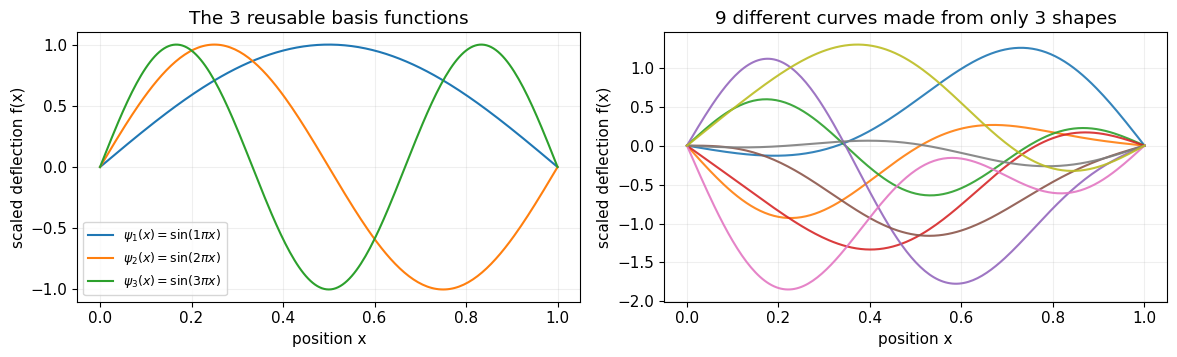

Feature / basis matrix shape: (201, 3)  = (positions, basis functions)


In [2]:
x = np.linspace(0, 1, 201)
N_MODES = 3

def sine_features(x, n=N_MODES):
    x = np.asarray(x).reshape(-1)
    return np.sin(np.pi * x[:, None] * np.arange(1, n+1)[None, :])

Phi = sine_features(x)                # rows: positions; columns: basis functions
A = rng.uniform(-1, 1, size=(9, N_MODES))
F = A @ Phi.T                         # rows: nine scaled deflection curves

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for j in range(N_MODES):
    axes[0].plot(x, Phi[:, j], label=fr'$\psi_{j+1}(x)=\sin({j+1}\pi x)$')
for f in F:
    axes[1].plot(x, f, alpha=.9)
axes[0].set_title('The 3 reusable basis functions')
axes[1].set_title('9 different curves made from only 3 shapes')
for ax in axes:
    ax.set(xlabel='position x', ylabel='scaled deflection f(x)')
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()
print('Feature / basis matrix shape:', Phi.shape, ' = (positions, basis functions)')

## 2. The primal view: directly combine the basis functions

Choose any coefficients $c_1,c_2,c_3$. The prediction is

$$\boxed{\hat f(x)=c_1\psi_1(x)+c_2\psi_2(x)+c_3\psi_3(x)
=\boldsymbol\phi(x)^T\mathbf c}$$

where the **feature vector of a position** is $\boldsymbol\phi(x)=[\psi_1(x),\psi_2(x),\psi_3(x)]^T$.

This is called the *primal* because we solve directly for the **3 coefficients attached to the 3 basis functions**. Notice the connection to FEM: $u(x)=\sum_jN_j(x)u_j$. The main difference in a function encoder is that the $\psi_j$ are **learned across tasks**, rather than hand-prescribed shape functions.

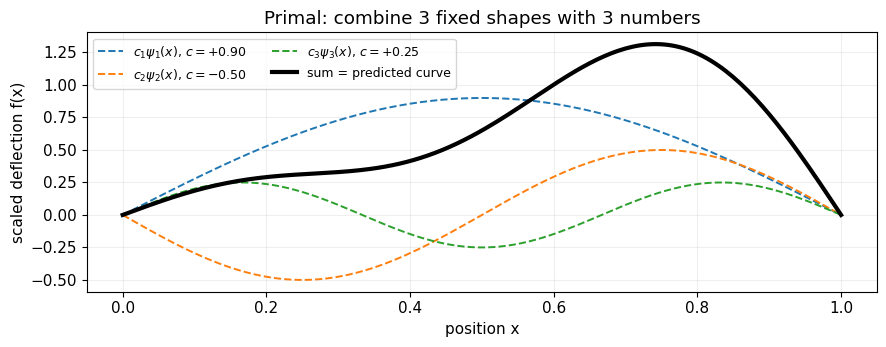

In [3]:
c_example = np.array([0.9, -0.5, 0.25])
pieces = Phi * c_example[None, :]
fig, ax = plt.subplots(figsize=(9, 3.6))
for j in range(N_MODES):
    ax.plot(x, pieces[:, j], lw=1.4, ls='--',
            label=fr'$c_{j+1}\psi_{j+1}(x)$, $c={c_example[j]:+.2f}$')
ax.plot(x, pieces.sum(axis=1), 'k', lw=3, label='sum = predicted curve')
ax.set(xlabel='position x', ylabel='scaled deflection f(x)',
       title='Primal: combine 3 fixed shapes with 3 numbers')
ax.legend(ncol=2, fontsize=9); plt.tight_layout(); plt.show()

## 3. What is a kernel? A dot product between the *features of two locations*

A kernel takes **two** positions, $x$ and $x'$, and returns **one** number:

$$\boxed{\kappa(x,x')=\boldsymbol\phi(x)^T\boldsymbol\phi(x')
=\sum_{j=1}^{n}\psi_j(x)\psi_j(x').}$$

The intuition is not that the two positions are physically close. Rather:

- At $x$, ask: **How strongly does each basis shape participate here?** This is the vector $\boldsymbol\phi(x)$.
- Ask the same question at $x'$.
- Multiply matching entries and add. A **positive** inner product means the feature patterns point in similar directions; **negative** means opposing patterns; **zero** means orthogonal feature vectors.

To *see* the dot product, temporarily use just two basis functions $\psi_1=\sin(\pi x)$ and $\psi_2=\sin(2\pi x)$. Every 1D position is mapped to a **point in 2D feature space**.

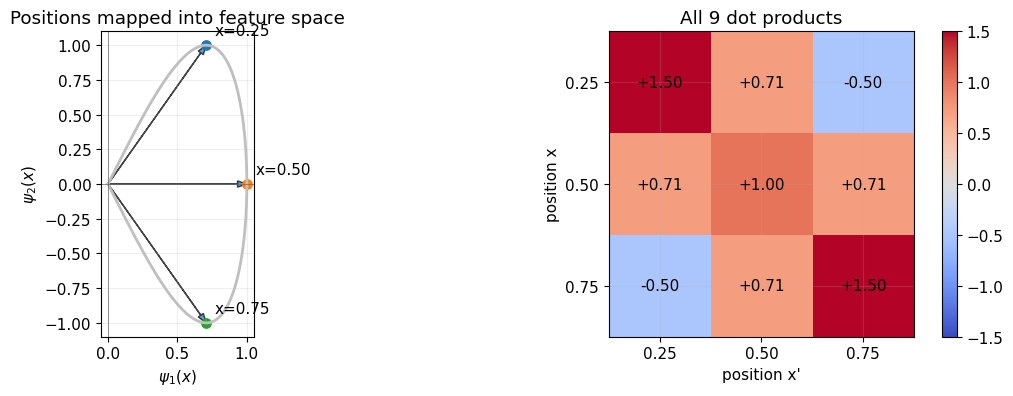

Feature vectors at x = 0.25 and x = 0.75: [0.707 1.   ] [ 0.707 -1.   ]
Their kernel similarity (dot product): -0.5


In [4]:
# A completely inspectable two-feature kernel.
def phi2(v):
    return sine_features(v, n=2)

locations = np.array([0.25, 0.50, 0.75])
features = phi2(locations)
K3 = features @ features.T

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.1))
curve_features = phi2(x)
axes[0].plot(curve_features[:, 0], curve_features[:, 1], color='0.75', lw=2)
for location, v in zip(locations, features):
    axes[0].arrow(0, 0, *v, head_width=.045, length_includes_head=True, alpha=.72)
    axes[0].scatter(*v, s=45)
    axes[0].annotate(f'x={location:.2f}', xy=v, xytext=(6, 7),
                     textcoords='offset points')
axes[0].axhline(0, lw=.5, color='0.4')
axes[0].axvline(0, lw=.5, color='0.4')
axes[0].set(xlabel=r'$\psi_1(x)$', ylabel=r'$\psi_2(x)$',
            title='Positions mapped into feature space', aspect='equal')
img = axes[1].imshow(K3, cmap='coolwarm', vmin=-np.max(abs(K3)),
                      vmax=np.max(abs(K3)))
axes[1].set_xticks(range(3), [f'{v:.2f}' for v in locations])
axes[1].set_yticks(range(3), [f'{v:.2f}' for v in locations])
axes[1].set(xlabel="position x'", ylabel='position x', title='All 9 dot products')
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f'{K3[i,j]:+.2f}', va='center', ha='center')
fig.colorbar(img, ax=axes[1], fraction=.046)
plt.tight_layout(); plt.show()
print('Feature vectors at x = 0.25 and x = 0.75:', features[0], features[2])
print('Their kernel similarity (dot product):', round(float(K3[0,2]), 3))

**Look at $x=0.25$ and $x'=0.75$.** They are halfway across the beam from one another, yet both have the same positive first-mode value and opposite second-mode values. Their kernel value is **negative** ($-0.5$). That is fine!

A valid kernel does **not** have to lie between 0 and 1, and it does **not** mean "nearby points are always more similar." Only the *whole kernel matrix* must be positive semidefinite.

A useful analogy: a kernel is like asking whether two locations have similar *modal fingerprints*. We choose or learn the fingerprint; the kernel measures its inner product.

## 4. A kernel is itself a function of position: $\kappa(\cdot,x')$

**Fix the second input $x'$.** Then $x\mapsto\kappa(x,x')$ becomes an ordinary curve, one for each reference location.

Compare two kernels:

1. **Modal / feature kernel** $\kappa_{\rm modes}(x,x')=\sum_{j=1}^3\sin(j\pi x)\sin(j\pi x')$.
2. **Gaussian / RBF kernel** $\kappa_{\rm RBF}(x,x')=\exp[-(x-x')^2/(2\ell^2)]$.

An RBF is a localized positive bump because it uses distance. A modal kernel is a sum of global modes: it can be **nonlocal and signed**. It is *not* a Green's function for the beam operator, even though both may be represented through modal expansions; a Green's function would require the correct inverse-operator weights, e.g. $1/(EI(j\pi)^4)$ in the beam sine expansion.

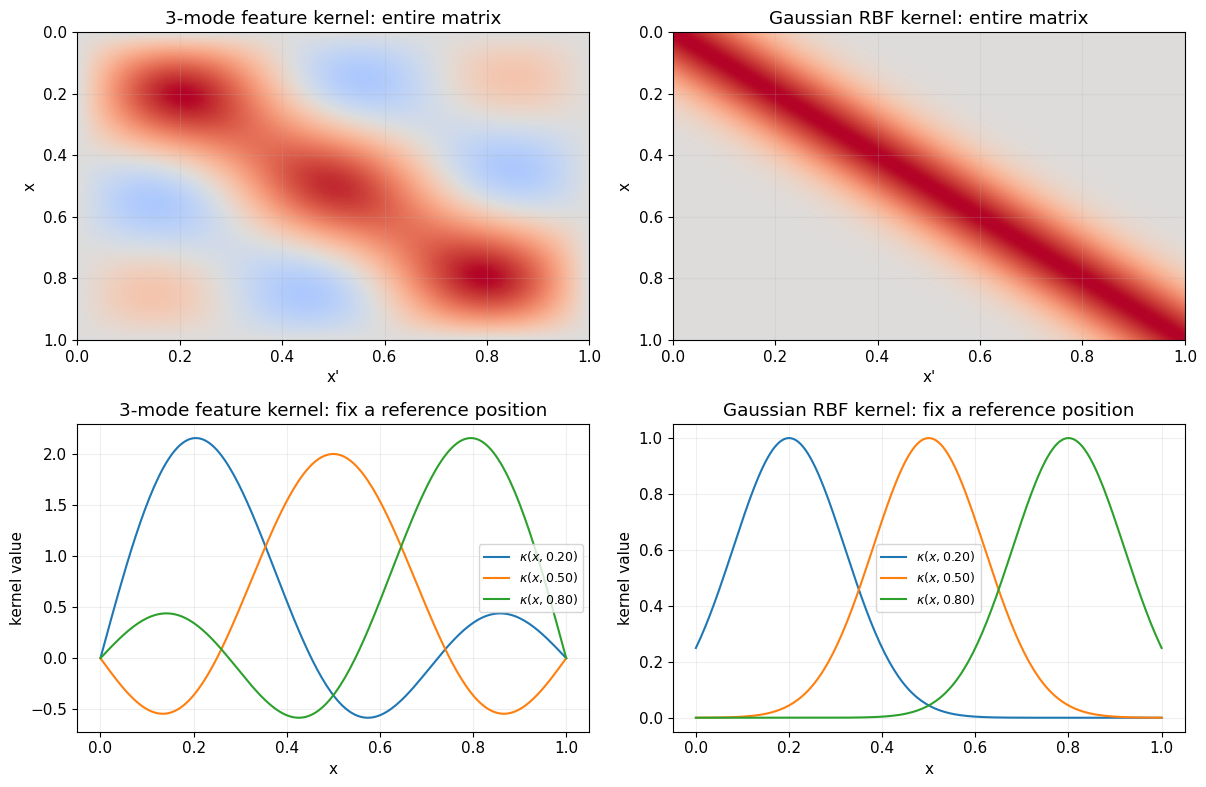

In [5]:
def feature_kernel(xa, xb, n=3):
    return sine_features(xa, n) @ sine_features(xb, n).T

def rbf_kernel(xa, xb, ell=0.12):
    xa = np.asarray(xa).reshape(-1, 1)
    xb = np.asarray(xb).reshape(1, -1)
    return np.exp(-.5 * ((xa - xb) / ell)**2)

reference_x = np.array([0.20, 0.50, 0.80])
fig, axes = plt.subplots(2, 2, figsize=(12.2, 8))
for col, (kernel, label) in enumerate([(feature_kernel, '3-mode feature kernel'),
                                       (rbf_kernel, 'Gaussian RBF kernel')]):
    K = kernel(x, x)
    vals = kernel(x, reference_x)
    bound = np.max(np.abs(K))
    axes[0, col].imshow(K, extent=[0, 1, 1, 0], cmap='coolwarm',
                        vmin=-bound, vmax=bound, aspect='auto')
    axes[0, col].set(title=f'{label}: entire matrix', xlabel="x'", ylabel='x')
    for j, ref in enumerate(reference_x):
        axes[1, col].plot(x, vals[:, j], label=fr"$\kappa(x,{ref:.2f})$")
    axes[1, col].set(title=f'{label}: fix a reference position', xlabel='x',
                     ylabel='kernel value')
    axes[1, col].legend(fontsize=9)
plt.tight_layout(); plt.show()

### Two different Gram matrices (the most common notation confusion)

Put $m$ input locations into a **feature matrix** $\Phi\in\mathbb R^{m\times n}$, with $\Phi_{ij}=\psi_j(x_i)$.

$$\underbrace{K=\Phi\Phi^T}_{m\times m\text{ : compares sample locations}},\qquad
\underbrace{G=\Phi^T\Phi}_{n\times n\text{ : compares basis columns}}.$$

- $K_{i\ell}=\kappa(x_i,x_\ell)$: the **kernel matrix** (also called the sample Gram matrix).
- $G_{jk}=\sum_i\psi_j(x_i)\psi_k(x_i)$: the **basis Gram matrix** (discrete inner products between basis functions). The paper's normalized version divides by $m$.

$K$ is a valid kernel matrix because it is **symmetric** and for every vector $v$, 

$$v^TKv=v^T\Phi\Phi^Tv=\|\Phi^Tv\|_2^2\ge0.$$

This is positive **semidefinite**, not necessarily positive definite: if $n<m$, the $m\times m$ kernel matrix has rank at most $n$, so it usually has many zero eigenvalues.

In [6]:
K = Phi @ Phi.T
G = Phi.T @ Phi
smallest = np.linalg.eigvalsh(K)[0]
print(f'Phi shape = {Phi.shape}; K = Phi Phi^T shape = {K.shape}; G = Phi^T Phi shape = {G.shape}')
print(f'K symmetry error = {np.max(np.abs(K-K.T)):.2e}')
print(f'smallest eigenvalue of K = {smallest:.2e} (roundoff near zero)')
print(f'rank(K) = {np.linalg.matrix_rank(K)}; number of basis functions = {Phi.shape[1]}')
assert np.allclose(K, K.T)
assert smallest > -1e-9
assert np.linalg.matrix_rank(K) <= Phi.shape[1]

Phi shape = (201, 3); K = Phi Phi^T shape = (201, 201); G = Phi^T Phi shape = (3, 3)
K symmetry error = 0.00e+00
smallest eigenvalue of K = -6.33e-14 (roundoff near zero)
rank(K) = 3; number of basis functions = 3


### A subtle but important point: the kernel is not uniquely determined by the function *span*

If we multiply $\psi_2$ by 3, the set of functions representable as $\sum c_j\psi_j$ does **not** change (we can divide its coefficient by 3). But the kernel $\sum_j\psi_j(x)\psi_j(x')$ **does** change, because the second direction gets 9 times more weight.

So the learned kernel encodes not just the available shapes but also the **geometry / regularization** chosen for their coefficients. Two basis sets can span the same space while inducing different kernels. This nuance is easy to miss when someone says "the learned function space *is* the kernel."

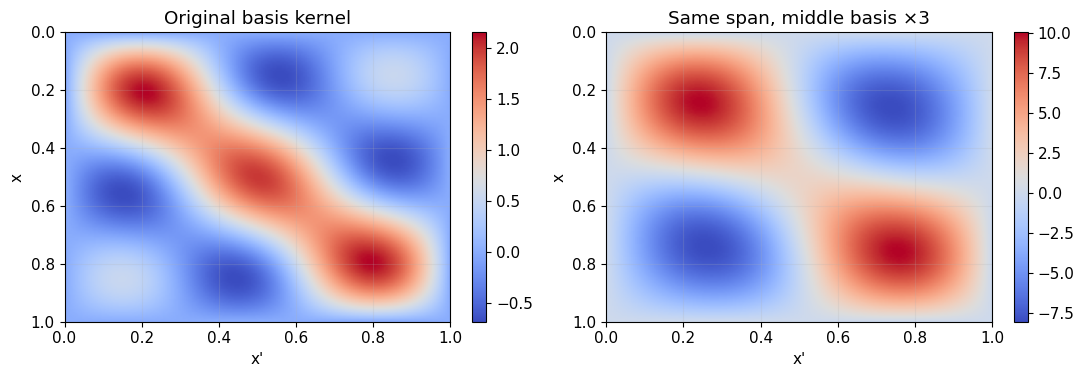

Same column span? True
Are the kernels the same? False


In [7]:
Phi_scaled = Phi @ np.diag([1.0, 3.0, 1.0])
K_scaled = Phi_scaled @ Phi_scaled.T
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, Ki, title in [(axes[0], K, 'Original basis kernel'),
                      (axes[1], K_scaled, 'Same span, middle basis ×3')]:
    im = ax.imshow(Ki, extent=[0, 1, 1, 0], cmap='coolwarm', aspect='auto')
    ax.set(title=title, xlabel="x'", ylabel='x')
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()
print('Same column span?', np.linalg.matrix_rank(np.column_stack([Phi, Phi_scaled])) == 3)
print('Are the kernels the same?', np.allclose(K, K_scaled))

## 5. The primal–dual identity: one predictor, two sets of unknowns

Take **one new beam deflection** and observe its values $y_i=f(x_i)+\text{noise}$ at $m$ positions. We already know the three basis functions; only their coefficients are unknown.

**Primal (solve for $n$ basis weights $c$):**

$$\hat{\mathbf c}=\arg\min_{\mathbf c}\left\{\|y-\Phi_{\rm obs}\mathbf c\|^2+\lambda\|\mathbf c\|^2\right\},\qquad
(\Phi_{\rm obs}^T\Phi_{\rm obs}+\lambda I_n)\hat{\mathbf c}=\Phi_{\rm obs}^Ty.$$

**Dual (solve for $m$ weights $\beta$, one per observed location):**

$$K_{\rm obs}=\Phi_{\rm obs}\Phi_{\rm obs}^T,\qquad
(K_{\rm obs}+\lambda I_m)\hat{\boldsymbol\beta}=y.$$

Then, for *any* query position $x_*$:

$$\boxed{\hat f_{\rm primal}(x_*)=\boldsymbol\phi(x_*)^T\hat{\mathbf c}},\qquad
\boxed{\hat f_{\rm dual}(x_*)=\sum_{i=1}^m\hat\beta_i\,\kappa(x_*,x_i)}.$$

We use the **unnormalized** least-squares objective above. The paper uses an average $\tfrac1m\sum_i(\cdot)^2+\lambda_{\rm paper}\|c\|^2$, so our code's $\lambda=m\lambda_{\rm paper}$.

Primal: solve matrix shape = (3, 3)
Dual:   solve matrix shape = (16, 16)
true c: [ 0.85 -0.6   0.35] | recovered c: [ 0.811 -0.598  0.346]
||c_hat - Phi_obs^T beta_hat||_inf = 1.6653345369377348e-16
max |primal prediction - dual prediction| = 6.661338147750939e-16


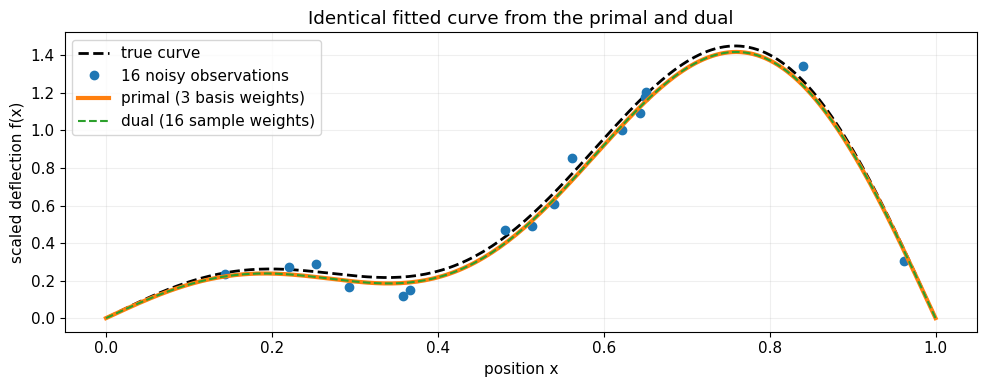

In [8]:
# A fully worked numerical experiment, using the same 3-mode feature map.
m_obs = 16
x_obs = np.sort(rng.uniform(0.03, 0.97, m_obs))
c_true = np.array([0.85, -0.60, 0.35])
noise_sd = 0.075
ridge_lambda = 0.20

y_true = sine_features(x) @ c_true
y_obs = sine_features(x_obs) @ c_true + noise_sd * rng.normal(size=m_obs)
Phi_obs = sine_features(x_obs)
K_obs = Phi_obs @ Phi_obs.T

# PRIMAL: three unknowns.
c_hat = np.linalg.solve(Phi_obs.T @ Phi_obs + ridge_lambda*np.eye(3), Phi_obs.T @ y_obs)
y_primal = sine_features(x) @ c_hat

# DUAL: sixteen unknowns.
beta_hat = np.linalg.solve(K_obs + ridge_lambda*np.eye(m_obs), y_obs)
y_dual = feature_kernel(x, x_obs) @ beta_hat

print('Primal: solve matrix shape =', (Phi_obs.T @ Phi_obs).shape)
print('Dual:   solve matrix shape =', K_obs.shape)
print('true c:', c_true, '| recovered c:', c_hat)
print('||c_hat - Phi_obs^T beta_hat||_inf =',
      np.max(np.abs(c_hat - Phi_obs.T @ beta_hat)))
print('max |primal prediction - dual prediction| =', np.max(np.abs(y_primal-y_dual)))
assert np.allclose(y_primal, y_dual, atol=1e-10)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, y_true, 'k--', lw=2, label='true curve')
ax.plot(x_obs, y_obs, 'o', ms=6, label='16 noisy observations')
ax.plot(x, y_primal, lw=3, label='primal (3 basis weights)')
ax.plot(x, y_dual, '--', lw=1.5, label='dual (16 sample weights)')
ax.set(xlabel='position x', ylabel='scaled deflection f(x)',
       title='Identical fitted curve from the primal and dual')
ax.legend(); plt.tight_layout(); plt.show()

### Why exactly do the predictions agree?

Start from the dual predictor and substitute the definition of the kernel:

$$
\begin{aligned}
\hat f(x)
&=\sum_{i=1}^m\hat\beta_i\underbrace{\kappa(x,x_i)}_{\sum_j\psi_j(x)\psi_j(x_i)}\\
&=\sum_{j=1}^n\psi_j(x)\underbrace{\left(\sum_{i=1}^m\hat\beta_i\psi_j(x_i)\right)}_{\hat c_j}\\
&=\sum_{j=1}^n\hat c_j\psi_j(x).
\end{aligned}
$$

The equation that does all the work is

$$\boxed{\hat{\mathbf c}=\Phi_{\rm obs}^T\hat{\boldsymbol\beta}}.$$

**Primal** = coefficients attached to **basis shapes**. **Dual** = coefficients attached to **observation-centered kernel functions**. They are *not two different physical models* or two different predictions here. The word **dual** refers to an alternative mathematical formulation of the same ridge-regression problem.

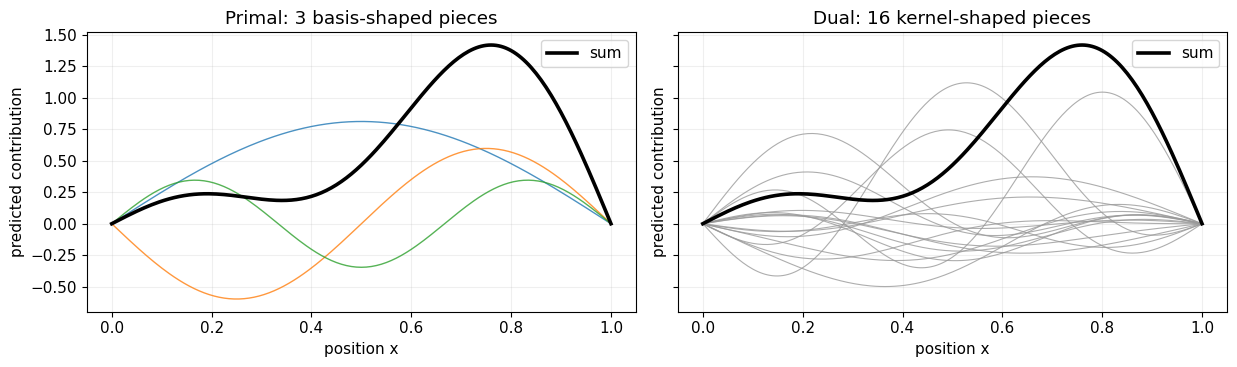

In [9]:
# Plot the actual pieces that get added in the two descriptions.
primal_pieces = sine_features(x) * c_hat[None, :]
dual_pieces = feature_kernel(x, x_obs) * beta_hat[None, :]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for j in range(primal_pieces.shape[1]):
    axes[0].plot(x, primal_pieces[:, j], lw=1, alpha=.8)
axes[0].plot(x, primal_pieces.sum(axis=1), color='black', lw=2.6, label='sum')
axes[0].set_title('Primal: 3 basis-shaped pieces')
for j in range(dual_pieces.shape[1]):
    axes[1].plot(x, dual_pieces[:, j], color='0.60', lw=.8, alpha=.8)
axes[1].plot(x, dual_pieces.sum(axis=1), color='black', lw=2.6, label='sum')
axes[1].set_title('Dual: 16 kernel-shaped pieces')
for ax in axes:
    ax.set(xlabel='position x', ylabel='predicted contribution')
    ax.legend()
plt.tight_layout(); plt.show()

## 6. Why use the primal if the dual is equivalent?

If you have $m=1{,}000$ measurements and $n=3$ learned basis functions:

| | Primal | Dual |
|---|---|---|
| Unknowns | 3 numbers ($c_j$) | 1,000 numbers ($\beta_i$) |
| Matrix solve | $3\times 3$ | $1{,}000\times1{,}000$ |
| Prediction | Evaluate 3 basis functions | Evaluate 1,000 kernels |
| Standard dense solve work | $O(mn^2+n^3)$ | $O(m^2n+m^3)$ |

This is the paper's scalability argument **when $n\ll m$**. Neither method eliminates the cost of evaluating features at the observations. The primal merely avoids forming and solving the big $m\times m$ kernel matrix. After training, you can compute a new function's coefficients from a small sample and evaluate it cheaply.

**Why ever choose dual?** For RBF kernels the feature map can be infinite-dimensional and is not explicitly constructed: the *kernel trick* gives us inner products directly. The dual can also be attractive if $m\ll n$.

A learned finite-feature kernel still *has* a dual, but we normally solve its **small primal problem**. "Without kernels" in the title means "without doing kernel-matrix regression," not "there is no mathematical kernel."

## 7. Now make the basis **learned**: a small function encoder

Everything so far used **hand-selected** sine modes, to make the kernel's meaning unmistakable. Low et al. instead train neural basis functions $\psi_j(x;\theta)$ across an entire family of curves.

**Two levels of learning** (the most important function-encoder distinction):

1. **Across many training functions:** update neural-network weights $\theta$ to learn reusable basis shapes $\psi_j$.
2. **For each new function:** freeze $\theta$; use only that function's observations to solve its small ridge regression for coefficients $c_j$.

The following minimal example uses a shared tanh MLP with **5 output heads** (five learned basis functions). It learns from many different 3-mode beam deflections—without being given their sine basis. Using five heads when the true family has three dimensions lets us explore **redundancy**.

The training loss uses a least-squares solve **inside** the neural-network training loop:

$$\Phi_\theta\longrightarrow \hat C_\theta=\operatorname{ridge}(\Phi_\theta,F)\longrightarrow
\mathcal{L}=\|F-\Phi_\theta\hat C_\theta\|^2+\mu\|\tfrac1M\Phi_\theta^T\Phi_\theta-I\|_F^2.$$

The last term is a **soft near-orthonormality penalty**, similar in spirit to the recommendation in the paper's §3. We distinguish training-grid length $M$ from the number of observations used to adapt to a *new* task.

Five neural basis functions trained across 140 curves
Test MSE on new curves (fit coefficients with frozen bases): 2.174e-06


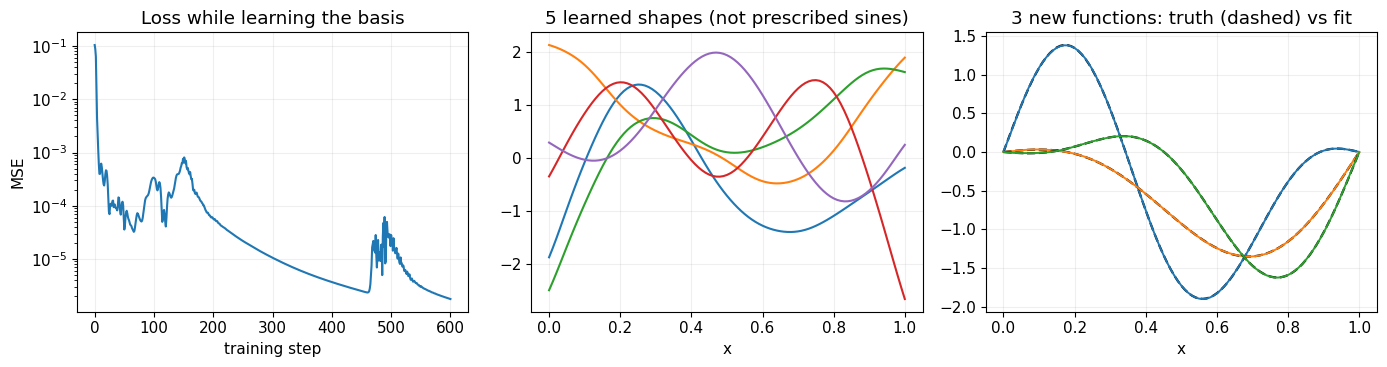

In [10]:
# Small CPU-friendly training experiment. Runs in seconds on typical CPUs.
M = 101
x_train_grid = np.linspace(0, 1, M)
A_train = rng.uniform(-1, 1, (140, 3))
A_test = rng.uniform(-1, 1, (24, 3))
F_train = torch.tensor(sine_features(x_train_grid) @ A_train.T, dtype=torch.float32)
F_test = torch.tensor(sine_features(x_train_grid) @ A_test.T, dtype=torch.float32)

class BasisMLP(nn.Module):
    def __init__(self, n_basis=5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, 48), nn.Tanh(),
                                 nn.Linear(48, 48), nn.Tanh(),
                                 nn.Linear(48, n_basis))
    def forward(self, x):
        # x is in physical [0, 1]; the network sees [-1, 1].
        return self.net(2*x-1)

basis_model = BasisMLP(n_basis=5)
optimizer = torch.optim.Adam(basis_model.parameters(), lr=.015)
eye5 = torch.eye(5)
loss_trace = []
for step in range(601):
    basis = basis_model(torch.tensor(x_train_grid[:, None], dtype=torch.float32))
    coef = torch.linalg.solve(basis.T @ basis + 1e-3*eye5, basis.T @ F_train)
    data_loss = ((basis @ coef - F_train)**2).mean()
    gram = basis.T @ basis / M
    loss = data_loss + .01 * ((gram-eye5)**2).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_trace.append(data_loss.detach().item())

with torch.no_grad():
    learned_phi = basis_model(torch.tensor(x_train_grid[:, None], dtype=torch.float32)).numpy()
    C_test = np.linalg.solve(learned_phi.T @ learned_phi + 1e-3*np.eye(5),
                             learned_phi.T @ F_test.numpy())
    test_recon = learned_phi @ C_test
    test_mse = np.mean((F_test.numpy()-test_recon)**2)

print(f'Five neural basis functions trained across {A_train.shape[0]} curves')
print(f'Test MSE on new curves (fit coefficients with frozen bases): {test_mse:.3e}')
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].semilogy(loss_trace)
axes[0].set(title='Loss while learning the basis', xlabel='training step', ylabel='MSE')
for j in range(5):
    axes[1].plot(x_train_grid, learned_phi[:, j], label=f'learned ψ{j+1}')
axes[1].set(title='5 learned shapes (not prescribed sines)', xlabel='x')
for j in range(3):
    axes[2].plot(x_train_grid, F_test.numpy()[:, j], 'k--', lw=1.6)
    axes[2].plot(x_train_grid, test_recon[:, j], lw=1.4)
axes[2].set(title='3 new functions: truth (dashed) vs fit', xlabel='x')
plt.tight_layout(); plt.show()

### The learned basis creates a learned kernel automatically

**Mechanics check:** Some learned *individual* basis curves in the preceding figure do not vanish at the supports. Their **fitted combinations** approximately satisfy the boundary conditions because the training functions do. The unconstrained basis network does not guarantee this for arbitrary coefficients; one could encode zero-displacement supports by multiplying each basis output by $x(1-x)$. This is a useful distinction between a flexible statistical representation and a physics-constrained basis.

Freeze the neural network. Each position now has a *learned* five-dimensional fingerprint $\boldsymbol\phi_\theta(x)$. The kernel is just

$$\boxed{\kappa_\theta(x,x')=\boldsymbol\phi_\theta(x)^T\boldsymbol\phi_\theta(x').}$$

**We did not train a separate kernel.** We trained basis functions and obtained their kernel by taking dot products. The kernel remains symmetric and positive semidefinite, and the primal and dual predictions still agree if we use the same ridge regularizer. This is the essence of §3.1 of the paper.

**Interpretation warning:** The learned kernel expresses similarity under this training distribution and the particular scaling of learned features. It does *not* automatically encode mechanical causality, a beam Green's function, or material parameters.

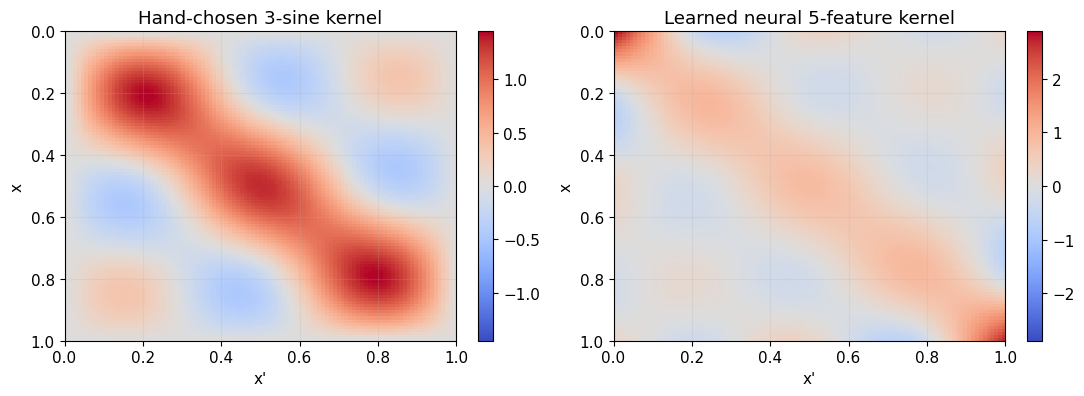

Kernel numerical rank <= number of neural outputs: 5 <= 5
Minimum learned-kernel eigenvalue (double-precision roundoff around zero): -4.6437766230525686e-14


In [11]:
K_learned = learned_phi.astype(np.float64) @ learned_phi.astype(np.float64).T
K_hand = sine_features(x_train_grid) @ sine_features(x_train_grid).T
# Normalize by mean diagonal for a fair visual comparison (not needed for PSD).
K_hand_plot = K_hand / np.mean(np.diag(K_hand))
K_learned_plot = K_learned / np.mean(np.diag(K_learned))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
for ax, Ki, title in [(axes[0], K_hand_plot, 'Hand-chosen 3-sine kernel'),
                      (axes[1], K_learned_plot, 'Learned neural 5-feature kernel')]:
    bound = np.max(np.abs(Ki))
    image = ax.imshow(Ki, extent=[0, 1, 1, 0], cmap='coolwarm',
                      vmin=-bound, vmax=bound, aspect='auto')
    ax.set(title=title, xlabel="x'", ylabel='x')
    fig.colorbar(image, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()
print('Kernel numerical rank <= number of neural outputs:',
      np.linalg.matrix_rank(K_learned), '<=', learned_phi.shape[1])
print('Minimum learned-kernel eigenvalue (double-precision roundoff around zero):',
      np.linalg.eigvalsh(K_learned)[0])

## 8. How many learned basis functions do we actually need?

We trained **5 neural outputs** for a function family constructed from **3 independent sine modes**. The model has extra capacity, but the fitted coefficient vectors across this family should concentrate in **roughly three directions**.

For each training function, fit a coefficient vector $c^{(r)}\in\mathbb R^5$. Collect these across functions and compute their covariance:

$$\Sigma=\frac{1}{N-1}\sum_{r=1}^N(c^{(r)}-\bar c)(c^{(r)}-\bar c)^T.$$

The paper uses the eigenvalues of $\Sigma$ to look for an elbow and choose an **effective rank** (e.g., 99% explained coefficient variance). It then describes **progressive training** and **train-then-prune** (§4). We demonstrate the rank diagnosis here, rather than re-running those longer algorithms.

**Nuance:** Coefficient variance equals physical function variance only if the basis is orthonormal in the chosen function-space inner product (or appropriately corrected by its Gram matrix). The covariance heuristic is **coordinate-dependent**. That is why soft orthonormality matters, and why the paper calls effective rank a proxy rather than an invariant physical dimension.

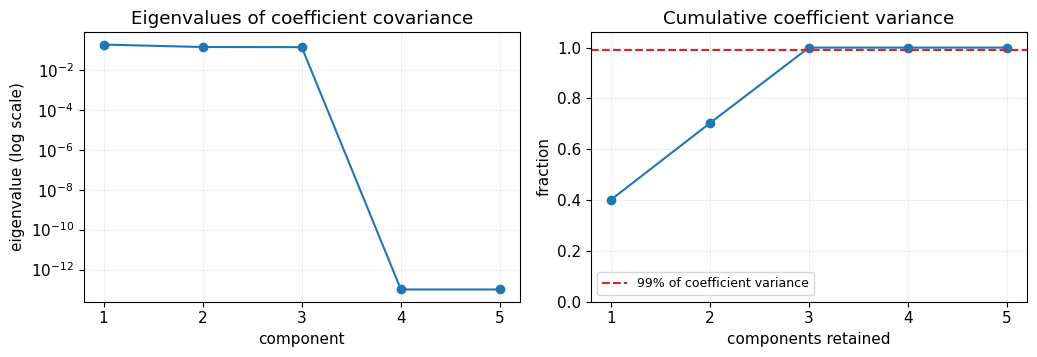

Eigenvalues: [0.19  0.144 0.142 0.    0.   ]
Number of directions retaining 99% coefficient variance: 3
True number of independent sine modes in this synthetic family: 3


In [12]:
with torch.no_grad():
    C_train = np.linalg.solve(learned_phi.T@learned_phi + 1e-3*np.eye(5),
                              learned_phi.T@F_train.numpy())
# C_train has shape (5 learned heads, 140 training functions).
Sigma = np.cov(C_train)
evals = np.linalg.eigvalsh(Sigma)[::-1]
evals = np.clip(evals, 0, None)
cumulative = np.cumsum(evals)/evals.sum()
rank99 = int(np.searchsorted(cumulative, .99) + 1)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].semilogy(np.arange(1, 6), np.maximum(evals, 1e-13), 'o-')
axes[0].set(title='Eigenvalues of coefficient covariance', xlabel='component',
            ylabel='eigenvalue (log scale)', xticks=range(1, 6))
axes[1].plot(range(1, 6), cumulative, 'o-')
axes[1].axhline(.99, color='tab:red', ls='--', label='99% of coefficient variance')
axes[1].set(title='Cumulative coefficient variance', xlabel='components retained',
            ylabel='fraction', ylim=(0, 1.06), xticks=range(1, 6))
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
print('Eigenvalues:', evals)
print('Number of directions retaining 99% coefficient variance:', rank99)
print('True number of independent sine modes in this synthetic family:', N_MODES)

### Optional: what if the response family does *not* have an exact finite basis?

The original notebook also uses moving vehicle loads. For a simply supported beam, a point load at position $a$ has a piecewise-cubic deflection, and moving $a$ through the interval excites **infinitely many** sine modes. Yet high-order modes are strongly suppressed by beam bending, so a small number of directions may explain **most** of the observed variability.

We compare the singular-value spectra of (a) our exact three-mode family and (b) random single-axle vehicle responses. This is a **PCA diagnostic on sampled deflections**, not neural-basis training. It illustrates the difference between *exact rank* and *effective rank*.

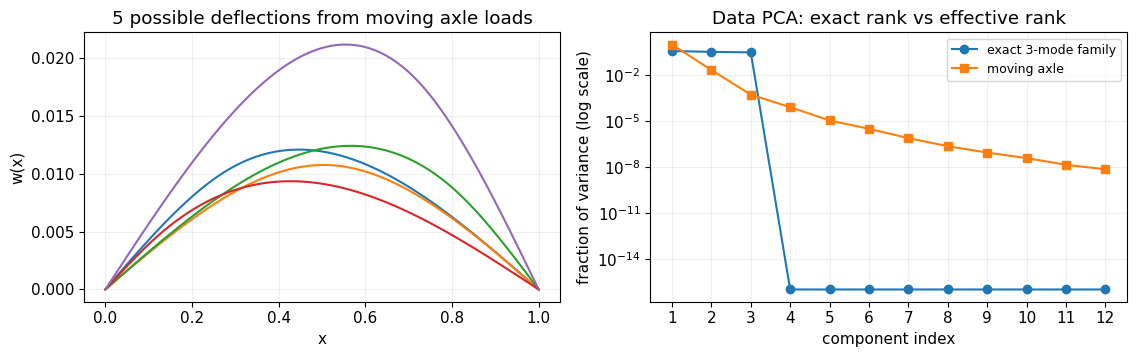

3-mode       components for 99% variance: 3; for 99.99%: 3
moving axle  components for 99% variance: 2; for 99.99%: 3


In [13]:
def point_load_deflection(x, P, a, L=1.0, EI=1.0):
    x = np.asarray(x)
    b = L-a
    left = P*b*x*(L**2-b**2-x**2)/(6*EI*L)
    xr = L-x
    right = P*a*xr*(L**2-a**2-xr**2)/(6*EI*L)
    return np.where(x<=a, left, right)

x_pca = np.linspace(0, 1, 121)
A_pca = rng.uniform(-1, 1, (250, 3))
F_exact = A_pca @ sine_features(x_pca).T
F_vehicle = np.array([point_load_deflection(x_pca, P, a) for P, a in
                      zip(rng.uniform(.5, 2, 250), rng.uniform(.08, .92, 250))])

def explained_variance_from_curves(F):
    # Rows are different functions; columns are grid positions.
    singular = np.linalg.svd(F-F.mean(axis=0), compute_uv=False)
    v = singular**2
    return v/v.sum()

v_exact = explained_variance_from_curves(F_exact)
v_vehicle = explained_variance_from_curves(F_vehicle)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
for i in range(5):
    axes[0].plot(x_pca, F_vehicle[i])
axes[0].set(title='5 possible deflections from moving axle loads', xlabel='x', ylabel='w(x)')
axes[1].semilogy(range(1, 13), np.maximum(v_exact[:12], 1e-16), 'o-', label='exact 3-mode family')
axes[1].semilogy(range(1, 13), np.maximum(v_vehicle[:12], 1e-16), 's-', label='moving axle')
axes[1].set(title='Data PCA: exact rank vs effective rank', xlabel='component index',
            ylabel='fraction of variance (log scale)', xticks=range(1, 13))
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
for label, v in [('3-mode', v_exact), ('moving axle', v_vehicle)]:
    print(f'{label:12s} components for 99% variance: {np.searchsorted(np.cumsum(v), .99)+1}; '
          f'for 99.99%: {np.searchsorted(np.cumsum(v), .9999)+1}')

## 9. Learned kernels on the bridge families, against the RBF kernel

Section 7 learned a kernel from a three-mode family, and Section 8 showed that moving axle loads have no exact finite basis.
Richer families give kernels with more structure.
Family A is a distributed load of five sine modes, $q(x) = \sum_{j=1}^{5} a_j\, j^4 \sin(j\pi x)$ with $a_j$ uniform in $[-1, 1]$, so the five deflection modes $a_j \sin(j\pi x)/\pi^4$ carry equal variance.
Family B is vehicles with one to three axles, spacing in $[0.1, 0.25]$, loads in $[0.5, 2]$, at random positions, using the point-load deflection of Section 8.
We train 12 basis functions on each family with the loss of Section 7, form $\kappa_\theta(x, x') = \boldsymbol\phi_\theta(x)^T \boldsymbol\phi_\theta(x')$, and compare with the RBF kernel $\exp(-(x - x')^2 / 2\ell^2)$ at $\ell = 0.1$, which is the same bump at every $x$.

In [14]:
import time

L = 1.0
x_grid = np.linspace(0, 1, 200)
modes5 = np.arange(1, 6)

def family_A(n):
    a = rng.uniform(-1, 1, (n, 5))                                       # load q = sum_j a_j j^4 sin(j pi x)
    return (a / np.pi**4) @ np.sin(np.pi * np.outer(modes5, x_grid))      # deflection mode j = q_j / (j pi)^4

def family_B(n):
    curves = []
    for _ in range(n):
        n_axles = rng.integers(1, 4)
        spacing = rng.uniform(0.1, 0.25, n_axles - 1)
        front = rng.uniform(0, L - spacing.sum())
        positions = front + np.concatenate([[0.0], np.cumsum(spacing)])
        loads = rng.uniform(0.5, 2.0, n_axles)
        curves.append(sum(point_load_deflection(x_grid, P, a) for a, P in zip(positions, loads)))
    return np.array(curves)

def train_basis(F_train, F_test, n_basis=12, steps=2000, lr=1e-2, lam=1e-3, mu=1e-2):
    """Function encoder with the loss of Section 7, in double precision. F is (n_functions, grid)."""
    model = BasisMLP(n_basis).double()
    xg = torch.tensor(x_grid[:, None])
    Ft, Fs = torch.tensor(F_train.T), torch.tensor(F_test.T)
    eye = torch.eye(n_basis, dtype=torch.float64)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    for step in range(steps):
        basis = model(xg)
        coef = torch.linalg.solve(basis.T @ basis + lam * eye, basis.T @ Ft)
        gram = basis.T @ basis / len(x_grid)
        loss = ((basis @ coef - Ft) ** 2).mean() + mu * ((gram - eye) ** 2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    with torch.no_grad():
        basis = model(xg)
        coef = torch.linalg.solve(basis.T @ basis + lam * eye, basis.T @ Fs)
        test_mse = ((basis @ coef - Fs) ** 2).mean().item()
        gram_dev = (basis.T @ basis / len(x_grid) - eye).abs().max().item()
    return model, basis.numpy(), test_mse, gram_dev

bases, models12, scales = {}, {}, {}
for name, make in [("A", family_A), ("B", family_B)]:
    F_tr, F_te = make(600), make(200)
    scale = np.sqrt(np.mean(F_tr ** 2))                                  # report MSE relative to the family's mean square
    t0 = time.time()
    model, Phi12, test_mse, gram_dev = train_basis(F_tr / scale, F_te / scale)
    bases[name], models12[name], scales[name] = Phi12, model, scale
    print(f"family {name}: 12 learned basis functions, test MSE {test_mse:.2e}, max|G - I| {gram_dev:.1e}, {time.time() - t0:.0f} s")

family A: 12 learned basis functions, test MSE 9.34e-05, max|G - I| 2.9e-03, 2 s


family B: 12 learned basis functions, test MSE 2.54e-06, max|G - I| 9.3e-05, 2 s


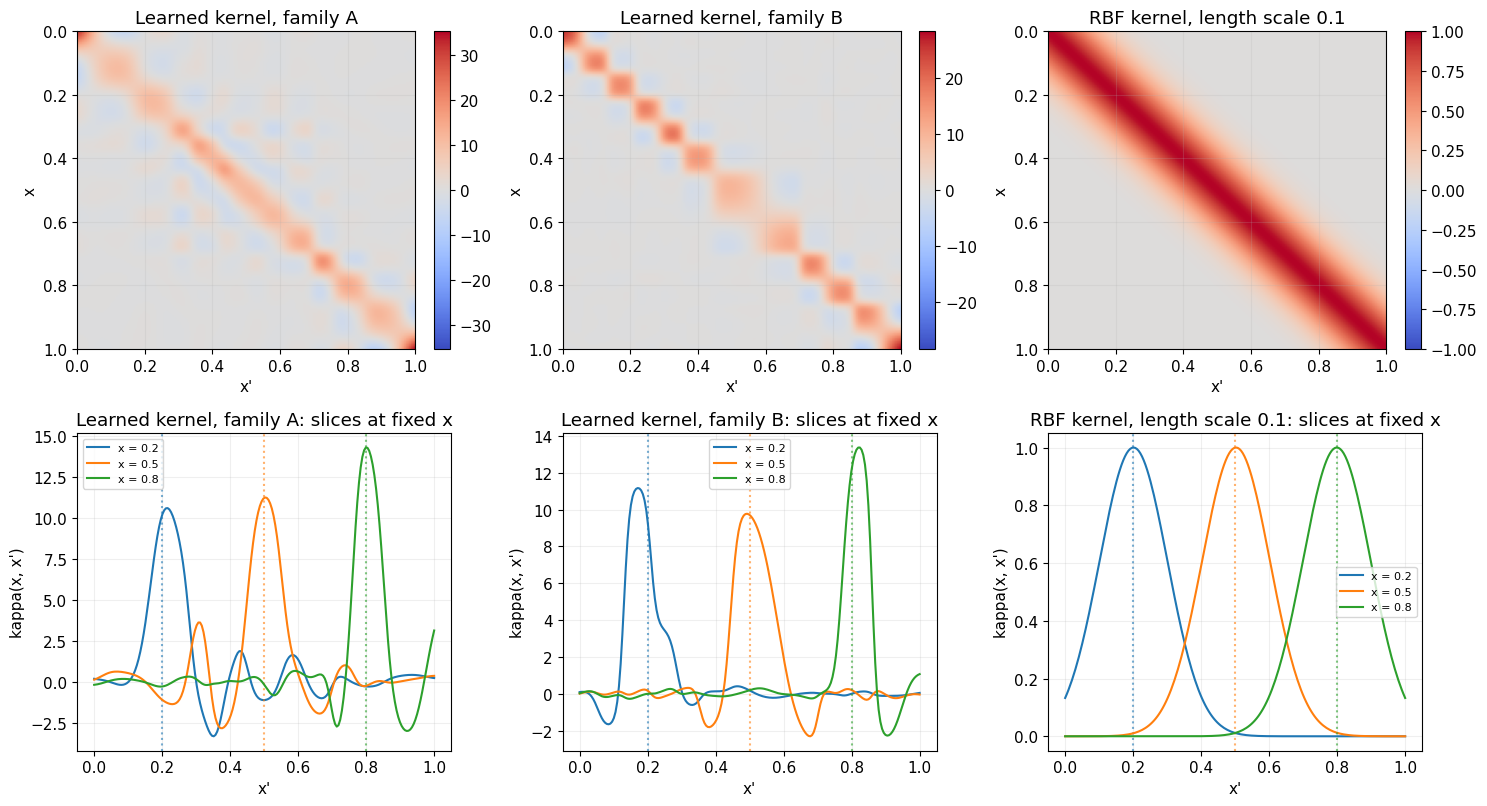

Learned kernel, family A      : rank 12, smallest eigenvalue -1.3e-13
Learned kernel, family B      : rank 12, smallest eigenvalue -1.1e-13
RBF kernel, length scale 0.1  : rank 31, smallest eigenvalue -1.2e-14
family A: kappa(x, x) at x = 0, 0.5, 1: 32.2, 11.3, 35.3
family B: kappa(x, x) at x = 0, 0.5, 1: 25.6, 9.7, 28.3


In [15]:
K_A = bases["A"] @ bases["A"].T
K_B = bases["B"] @ bases["B"].T
K_rbf = rbf_kernel(x_grid, x_grid, ell=0.1)
kernels = [("Learned kernel, family A", K_A), ("Learned kernel, family B", K_B), ("RBF kernel, length scale 0.1", K_rbf)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, (title, K) in zip(axes[0], kernels):
    bound = np.abs(K).max()
    image = ax.imshow(K, extent=[0, 1, 1, 0], cmap="coolwarm", vmin=-bound, vmax=bound, aspect="auto")
    ax.set(title=title, xlabel="x'", ylabel="x")
    fig.colorbar(image, ax=ax, fraction=0.046)
for ax, (title, K) in zip(axes[1], kernels):
    for x0, c in zip([0.2, 0.5, 0.8], ["tab:blue", "tab:orange", "tab:green"]):
        i0 = np.argmin(np.abs(x_grid - x0))
        ax.plot(x_grid, K[i0], color=c, label=f"x = {x0}")
        ax.axvline(x0, color=c, ls=":", alpha=0.6)
    ax.set(title=f"{title}: slices at fixed x", xlabel="x'", ylabel="kappa(x, x')")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for title, K in kernels:
    eig = np.linalg.eigvalsh(K)
    print(f"{title:30s}: rank {np.linalg.matrix_rank(K)}, smallest eigenvalue {eig[0]:.1e}")
for name, K in [("A", K_A), ("B", K_B)]:
    i = [np.argmin(np.abs(x_grid - v)) for v in (0.0, 0.5, 1.0)]
    print(f"family {name}: kappa(x, x) at x = 0, 0.5, 1: {K[i[0], i[0]]:.1f}, {K[i[1], i[1]]:.1f}, {K[i[2], i[2]]:.1f}")

All three kernels concentrate near the diagonal $x = x'$, so nearby points are similar under each of them, and the resemblance ends there.
The RBF kernel is the same Gaussian of width $\ell$ at every $x$, and its slices are translated copies of one bump of height 1.
The learned kernels depend on the family.
Their slices change height and width with $x$, they have side lobes of both signs, and family A and family B give different kernels on the same deck.
For a near-orthonormal basis the kernel depends only on the span, because an orthogonal change of basis leaves $\boldsymbol\phi(x)^T\boldsymbol\phi(x')$ unchanged, so training chooses the span and the span decides the kernel.
Each learned $200 \times 200$ matrix has rank 12, one per basis function, while the RBF matrix has rank 31 at the same tolerance.

The learned kernels are also largest at the corners $(0, 0)$ and $(1, 1)$.
The printed diagonal gives $\kappa(0, 0) = 32.2$ and $\kappa(1, 1) = 35.3$ against $\kappa(0.5, 0.5) = 11.3$ for family A, and 25.6 and 28.3 against 9.7 for family B.
Every deflection of both families vanishes at the supports, so the training data never asks for anything there, and some of the 12 basis functions take large values at the ends that cancel in every fitted combination.
The kernel weighs those directions as much as the ones the family uses, which is the interpretation warning of Section 7 in numbers.

### What the two predictors are made of

Section 5 showed the primal and dual pieces for the hand-chosen three-mode kernel.
With a learned basis and a truck that is not in the training set, the same picture separates the two constructions.
Kernel ridge regression with the RBF kernel adds one piece $\beta_l\,\kappa(x, x_l)$ per sample, so its predictor is built from $m$ pieces that move with the data.
The function encoder adds the same 12 learned basis functions with new weights, whatever $m$ is.
The figure draws both for 20 and for 80 noisy samples of the truck deflection, thin lines for the weighted pieces and a thick line for their sum.

RBF kernel ridge, m = 20: 20 pieces: RMSE 0.027, largest |piece| 14.18, largest |sum| 2.50
function encoder, m = 20: 12 pieces: RMSE 0.289, largest |piece| 2.91, largest |sum| 2.51
RBF kernel ridge, m = 80: 80 pieces: RMSE 0.013, largest |piece| 11.98, largest |sum| 2.52
function encoder, m = 80: 12 pieces: RMSE 0.019, largest |piece| 3.08, largest |sum| 2.51


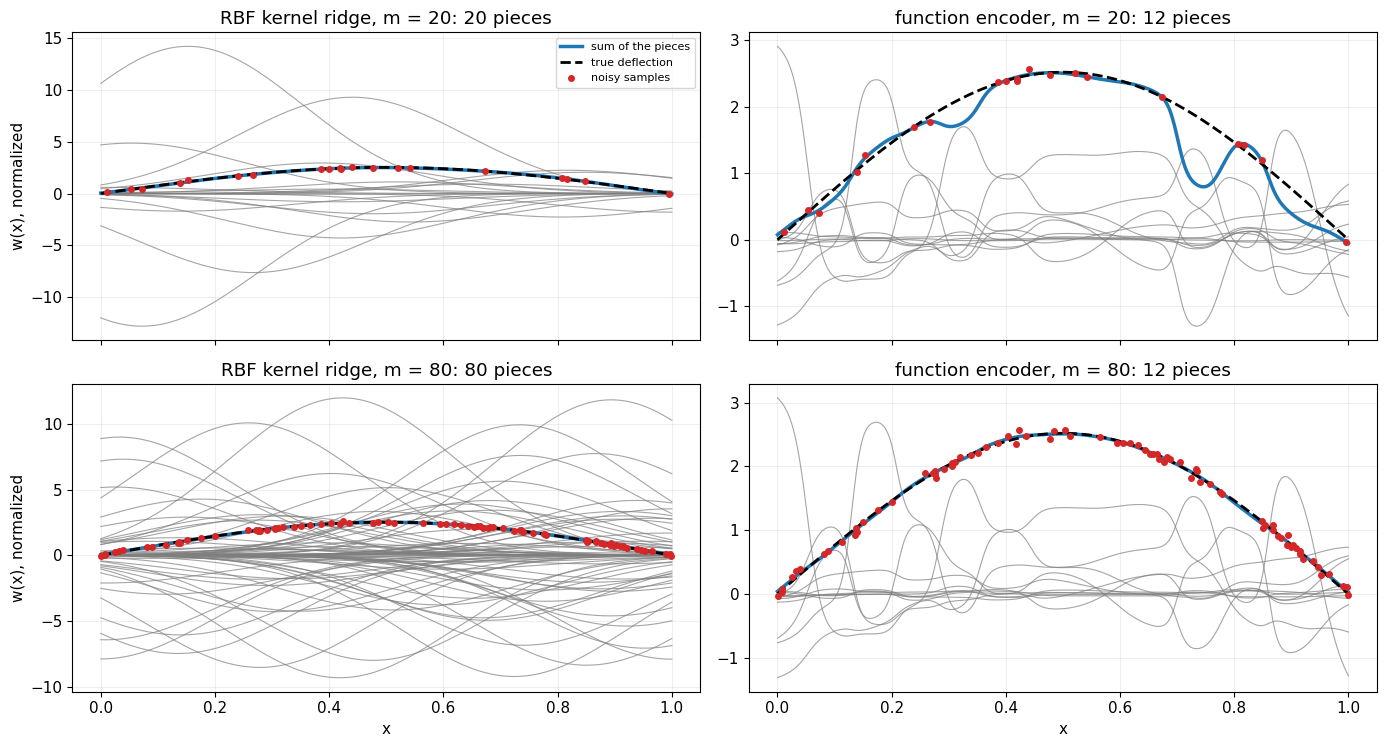

In [16]:
truck_positions, truck_loads = np.array([0.30, 0.45, 0.65]), np.array([0.8, 1.6, 1.6])
sigma_obs, lam_fit, ell_rbf = 0.05, 1e-2, 0.2
x_fine = np.linspace(0, 1, 500)
scale_B = scales["B"]
w_truck = sum(point_load_deflection(x_fine, P, a) for a, P in zip(truck_positions, truck_loads)) / scale_B
with torch.no_grad():
    Phi_fine = models12["B"](torch.tensor(x_fine[:, None])).numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 7.6), sharex=True)
for row, m_obs in enumerate([20, 80]):
    xo = np.sort(rng.uniform(0, 1, m_obs))
    yo = sum(point_load_deflection(xo, P, a) for a, P in zip(truck_positions, truck_loads)) / scale_B + sigma_obs * rng.standard_normal(m_obs)
    b = np.linalg.solve(rbf_kernel(xo, xo, ell_rbf) + lam_fit * np.eye(m_obs), yo)
    pieces_rbf = rbf_kernel(x_fine, xo, ell_rbf) * b[None, :]
    with torch.no_grad():
        Po = models12["B"](torch.tensor(xo[:, None])).numpy()
    c = np.linalg.solve(Po.T @ Po + lam_fit * np.eye(Po.shape[1]), Po.T @ yo)
    pieces_fe = Phi_fine * c[None, :]
    for ax, pieces, title in [(axes[row, 0], pieces_rbf, f"RBF kernel ridge, m = {m_obs}: {m_obs} pieces"),
                              (axes[row, 1], pieces_fe, f"function encoder, m = {m_obs}: {Po.shape[1]} pieces")]:
        ax.plot(x_fine, pieces, color="tab:gray", lw=0.8, alpha=0.7)
        ax.plot(x_fine, pieces.sum(axis=1), color="tab:blue", lw=2.5, label="sum of the pieces")
        ax.plot(x_fine, w_truck, "k--", lw=2, label="true deflection")
        ax.plot(xo, yo, "o", color="tab:red", ms=4, label="noisy samples")
        ax.set(title=title, ylabel="w(x), normalized" if ax is axes[row, 0] else None)
        rmse = np.sqrt(np.mean((pieces.sum(axis=1) - w_truck) ** 2))
        print(f"{title}: RMSE {rmse:.3f}, largest |piece| {np.abs(pieces).max():.2f}, largest |sum| {np.abs(pieces.sum(axis=1)).max():.2f}")
for ax in axes[1]:
    ax.set_xlabel("x")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

With 20 samples the kernel predictor is a sum of 20 pieces, and with 80 samples a sum of 80.
The pieces are large and cancel.
Their largest value is 14.18 at $m = 20$ and 11.98 at $m = 80$, while the sum never exceeds 2.52, so most of each piece is undone by its neighbors.
The function encoder uses the same 12 pieces for both sample counts, and the largest piece is 2.91 and 3.08, the size of the deflection itself.
The samples only change the 12 weights.

The sample count still matters for the encoder, through the weights.
With 20 noisy samples and 12 free weights the fit wiggles between the samples, with RMSE 0.289 against 0.027 for the kernel, and with 80 samples it reaches 0.019 against 0.013.
Twelve basis functions are more than the vehicle family needs, as the effective rank of Section 8 showed, and the surplus directions are free to fit noise.
A smaller basis, or a larger ridge, removes them.

## 10. Summary

| Term | Plain-language interpretation |
|---|---|
| Basis $\psi_j(x)$ | A reusable **shape** used to build many functions |
| Feature vector $\phi(x)$ | A location's **modal fingerprint** |
| Kernel $\kappa(x,x')$ | The **dot product of two fingerprints** (the induced similarity) |
| Primal coefficients $c_j$ | Weights attached to **basis functions** |
| Dual coefficients $\beta_i$ | Weights attached to **observed locations**, through $\kappa(\cdot,x_i)$ |

The paper's main result is the bridge between *learned neural basis representations* and *kernel-method theory*, and its compactness methods seek a small useful number of basis functions. The kernel does not provide extra mechanics by itself; physical constraints have to enter through the training data, model architecture, basis selection, or objectives.

**Exercises (edit the indicated cells and rerun):**

1. In §3, replace the two sine features by $[\sin(\pi x),\sin(3\pi x)]$. What happens to the similarity between $x=.25$ and $x=.75$? What does this tell you about what a kernel *means*?
2. In §5, change the number of observations from 16 to 6 or 50, and change the noise level and $\lambda$. Check that primal and dual still agree even as the quality of the fitted curve changes.
3. In §4, scale one basis function by 3. The representable function family is unchanged, but the kernel changes. Why does a fixed ridge penalty then favor a different prediction?

**More advanced caveats:** a $d$-dimensional **parameter space** need not mean a $d$-dimensional **linear function space**; coefficient PCA is basis-dependent unless the function-space metric is handled; and the paper's finite-sample guarantees apply under specified boundedness and fixed-basis assumptions—they are not general guarantees of physical correctness under contact or distribution shift.

**References:** Low, Rommel, Miller, Thorpe & Topcu (2025), *Function Spaces Without Kernels: Learning Compact Hilbert Space Representations*, arXiv:2509.20605, especially equations (1)–(6), Proposition 1, §4, and the examples in §6. The first version of this notebook (commit 57a08af of the course repository) includes more expensive implementations of progressive training and train-then-prune; this rewrite intentionally emphasizes the kernel intuition and the core primal–dual identity before those algorithms.